
# Fase 3 — Análisis de Datos

## Notebook 02: Análisis Exploratorio (EDA)

**Proyecto:** Pokémon Team Recommender

### Objetivo

Explorar las distribuciones, relaciones y patrones presentes en
los datos CLEAN de 151 Pokémon de primera generación.

### Preguntas de análisis

1. ¿Cómo se distribuyen las seis estadísticas base?
2. ¿Qué Pokémon presentan mayores valores en cada estadística?
3. ¿Qué relaciones existen entre las estadísticas?
4. ¿Qué tipos aparecen con mayor frecuencia?
5. ¿Cómo se distribuyen las debilidades y resistencias defensivas?
6. ¿Qué características podrían resultar útiles para el clustering?

### Alcance

El análisis es descriptivo y exploratorio.

No se entrenarán modelos ni se aplicará PCA o clustering
durante esta etapa.


In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

def find_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "data" / "clean").is_dir():
            if (path / "ingenieria").is_dir():
                return path

    raise FileNotFoundError(
        "No se encontró la raíz del proyecto."
    )

ROOT = find_root(Path.cwd())
CLEAN = ROOT / "data" / "clean"

pokemon = pd.read_csv(CLEAN / "pokemon.csv")
stats = pd.read_csv(CLEAN / "pokemon_stats.csv")
pokemon_types = pd.read_csv(CLEAN / "pokemon_types.csv")
types = pd.read_csv(CLEAN / "types.csv")
defensive = pd.read_csv(
    CLEAN / "pokemon_defensive_profile.csv"
)

print("Pokémon:", len(pokemon))
print("Estadísticas:", len(stats))
print("Relaciones de tipos:", len(pokemon_types))
print("Tipos:", len(types))
print("Perfiles defensivos:", len(defensive))


Pokémon: 151
Estadísticas: 906
Relaciones de tipos: 218
Tipos: 18
Perfiles defensivos: 2718


In [2]:

# Estadísticas base por categoría

summary_stats = (
    stats.groupby("stat_name")["base_stat"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(summary_stats)


,count,mean,median,std,min,max
stat_name,,,,,,
attack,151,72.91,70.0,26.76,5,134
defense,151,68.23,65.0,26.92,5,180
hp,151,64.21,60.0,28.59,10,250
special-attack,151,67.14,65.0,28.53,15,154
special-defense,151,66.09,65.0,24.21,20,125
speed,151,69.07,70.0,27.02,15,150


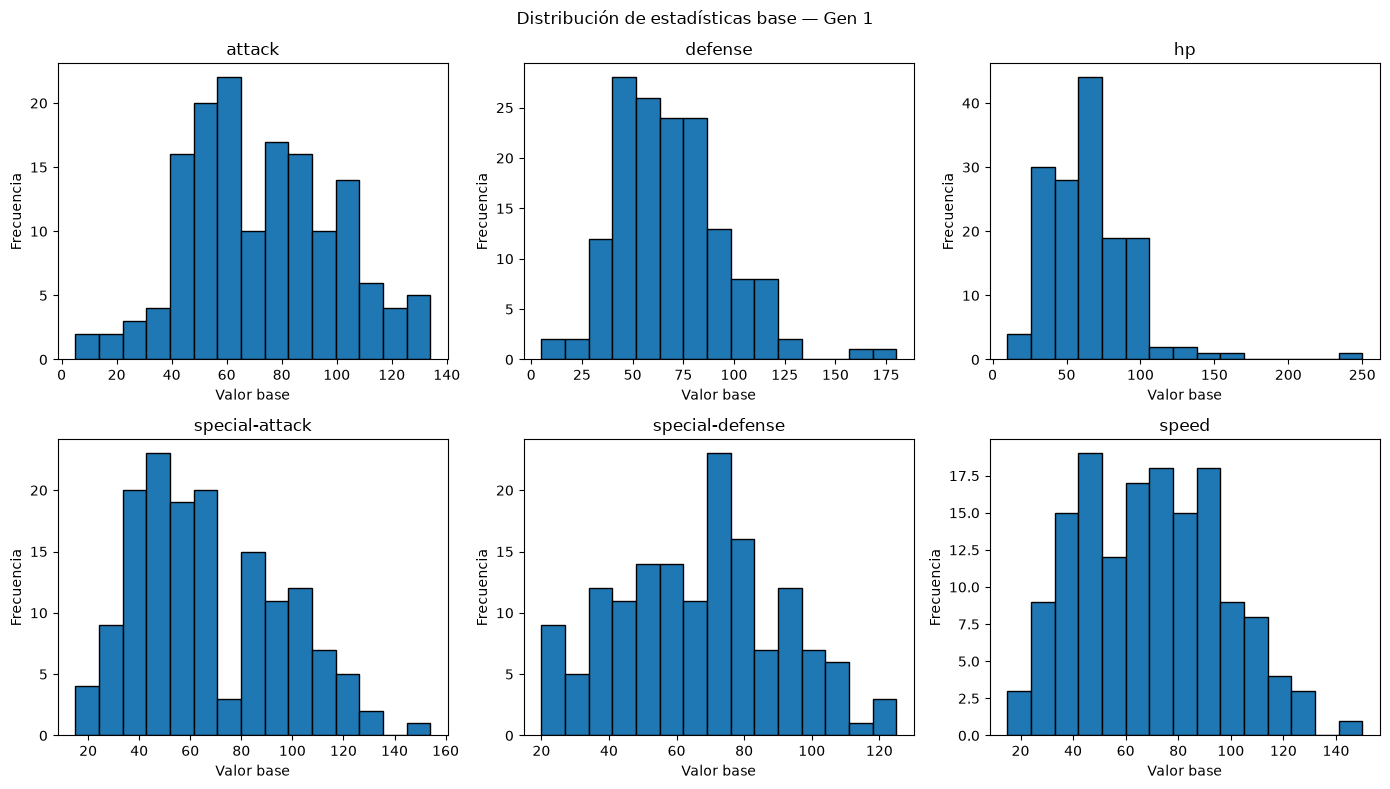

In [3]:

# Distribución de las seis estadísticas base

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

stat_names = sorted(stats["stat_name"].unique())

for ax, stat_name in zip(axes.flat, stat_names):
    values = stats.loc[
        stats["stat_name"] == stat_name,
        "base_stat"
    ]

    ax.hist(values, bins=15, edgecolor="black")
    ax.set_title(stat_name)
    ax.set_xlabel("Valor base")
    ax.set_ylabel("Frecuencia")

plt.suptitle(
    "Distribución de estadísticas base — Gen 1"
)
plt.tight_layout()
plt.show()
